# Updating the Level with Recent Demand

Notebook 05 ended with a model (`m4`) that has honest hourly intervals but a center that drifts too low as demand grows and we saw Notebook 4 also couldn't keep up with the growing demand. 

We tried five ways of letting the level move using only the training years, and none worked: 
    - 2021–2023 alone can't tell a lasting shift from a one-off surprise so we need a way to track this

Here we use information the model hasn't had so far which is the actual demand as it comes in.

Each day look at how far off the model has been recently and correct for it before forecasting. 

Done the Bayesian way:
- `prior`: what offsets usually look like 
- `data` the recent daily errors
- `posterior`: a corrected forecast, with the interval widened by how unsure the correction is

Game plan:
1. Rebuild `m4`'s forecasts from the saved samples, and check they match notebook 05.
2. Look at how the errors behave day to day: 
    - do they persist long enough to be worth correcting?
3. Try the simplest correction which is adding the average recent error, then the Bayesian update.
4. Choose the settings on 2024 (validation), then score the test period.

In [1]:
import sys; sys.path.append("..")

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error

#the model pieces built in notebook 05, collected in src/
from src.bayes_model import load_features, build_X, slot_index, predictive_draws, DEMAND_SCALE

SEED = 1145
RESULTS = Path("../results")

We updated src to use what we built in the previous notebook: 
- `src/bayes_model.py` holds the functions developed step by step in notebook 05 (`design`, `full_slots`, `build_X`, `slot_index`) plus `predictive_draws` 
- That last one is the posterior predictive (`X @ beta + noise`), done in numpy on 1,000 random posterior draws, because all draws x 15k test hours would need several GB. 
- The first check below confirms it reproduces notebook 05's numbers.

In [2]:
con = duckdb.connect("../data/grid.duckdb", read_only=True) #load
con.sql("SET TimeZone = 'UTC'") #set time

df = load_features(con) #get data using build function
train = df[df["split"] == "train"].reset_index(drop=True) #split into parts
valid = df[df["split"] == "valid"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)

print(f"train {len(train)}, valid {len(valid)}, test {len(test)}") #check sizes

#saved samples from notebook 05
idata_m4_full = az.from_netcdf(RESULTS / "idata_m4_full.nc") #m4 fit on 2021-2023 (for choosing settings on 2024)
idata_m4_final = az.from_netcdf(RESULTS / "idata_m4_final.nc") #m4 refit on 2021-2024 (for the test period)
idata_m5e = az.from_netcdf(RESULTS / "idata_m5e_sub.nc") # size of monthly surprises

train 26240, valid 8784, test 14584


In [3]:
def scores(y_draws, actual, name, mask=None): #function to score with (probably should have added this to src as well but is easy to build)
    '''
    Point forecast (median) and 90% interval scores
    '''

    #get marks 
    mask = np.ones(len(actual), bool) if mask is None else mask
    lo, hi = np.percentile(y_draws, 5, axis=0), np.percentile(y_draws, 95, axis=0)
    med = np.median(y_draws, axis=0)
    a, lo, hi, med = actual[mask], lo[mask], hi[mask], med[mask]

    return pd.DataFrame({
        "model": [name],
        "mae_mwh": [mean_absolute_error(a, med)],
        "mape_pct": [100 * mean_absolute_percentage_error(a, med)],
        "rmse_mwh": [root_mean_squared_error(a, med)],
        "bias_mwh": [np.mean(med - a)],
        "coverage_pct": [100 * np.mean((a >= lo) & (a <= hi))],
        "width_mwh": [np.mean(hi - lo)],
    }).round(2)


#m4's 2024 forecast rebuilt from the saved samples
y_va = predictive_draws(idata_m4_full, build_X(valid), slot_index(valid), seed=SEED) #predict
a_va = valid["demand_mwh"].values

scores(y_va, a_va, "m4 on 2024 (expect ~2.7% MAPE, ~-67 bias, ~92% coverage, ~800 width)")

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh,coverage_pct,width_mwh
0,"m4 on 2024 (expect ~2.7% MAPE, ~-67 bias, ~92%...",184.28,2.73,235.26,-67.21,91.91,799.76


Matches notebook 05 (2.7% MAPE, −67 MWh bias, 91.9% coverage, ~800 MWh wide), so the rebuilt forecasts are the same model.

## Step 1 -> Check error day to day behavior

We need this correction from recent demand to mean something so it needs to persist if we are going to care about it. 
If daily errors were independent, yesterday's error would say nothing about today, and correcting would just add noise.

Work with daily average errors which is `actual − forecast median, averaged over each Pacific day`.
Hourly errors are highly correlated hour to hour, so 24 hours of one day carry far less than 24 independent pieces of information so we use 1 number per day

daily average error: mean 67, sd 156 MWh
correlation with  1 day(s) earlier: 0.57
correlation with  2 day(s) earlier: 0.33
correlation with  3 day(s) earlier: 0.26
correlation with  7 day(s) earlier: 0.15
correlation with 14 day(s) earlier: 0.13
correlation with 30 day(s) earlier: -0.08


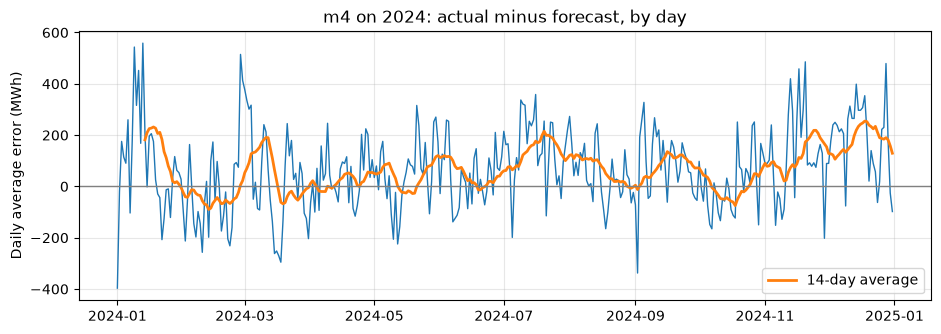

In [4]:
def daily_errors(y_draws, data):
    '''
    Daily average error (actual - forecast median), by Pacific date. 
    Returns-> daily series date per hour
    '''
    resid = data["demand_mwh"].values - np.median(y_draws, axis=0)
    dates = data["period_utc"].dt.tz_convert("America/Los_Angeles").dt.date.values

    return pd.Series(resid).groupby(dates).mean(), dates


daily_va, dates_va = daily_errors(y_va, valid)

print(f"daily average error: mean {daily_va.mean():.0f}, sd {daily_va.std():.0f} MWh")

for lag in [1, 2, 3, 7, 14, 30]: #check days back
    print(f"correlation with {lag:2d} day(s) earlier: {daily_va.autocorr(lag):.2f}")

#plot daily errors 
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(pd.to_datetime(daily_va.index), daily_va.values, linewidth=1) #daily
ax.plot(pd.to_datetime(daily_va.index), daily_va.rolling(14).mean().values, linewidth=2, label="14-day average") #14 day average

ax.axhline(0, color="gray", linewidth=1)
ax.set_ylabel("Daily average error (MWh)")
ax.set_title("m4 on 2024: actual minus forecast, by day")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

looks like errors persist for a few days and then fade:

- The daily average error is 67 MWh on average and fluctuates by 156 MWh day to day.
- Correlation with the day before is 0.57, then 0.33 (2 days), 0.26 (3 days), 0.15 (7 days), and about zero by a month.

So a bad day predicts a somewhat bad next day (weather systems last a few days), but most of that is gone within a week. 
Two things that we see with the errors:
- a slow offset from the 67 average which is what growth looks like
- short weather driven runs of a few days 

A correction should catch the first without go after the second since we are trying to get the offset here and have done fine with the weather already. 
This means averaging over enough days that one cold snap doesn't dominate 

The plot shows both: the daily line jumps around, while the 14-day average stays mostly above zero through 2024.

## Step 2 -> add the average recent error

For each day (D) shift every hour's forecast by the average daily error over the last N days.

- Timing: a day-ahead forecast for day D is made during day D−1, so only days up to D−2 are complete. 
    - The window is days D−1−N … D−2. Being conservative here means the correction is something that could really be run each morning.

we will choose the window by lowest 2024 MAPE, as long as coverage stays good (within ~88–94%). 
Corrections are chosen on 2024 only; the test period is scored once at the end.

In [5]:
def window_offsets(daily, n_days):
    '''
    Function to get the window offsets:
        Offset for each day = average daily error over the n_days before day D-1 (days D-1-n ... D-2)
    Return -> panda series
    '''
    vals = daily.values
    out = np.zeros(len(vals))
    for i in range(len(vals)):
        window = vals[max(0, i - 1 - n_days):max(0, i - 1)]
        out[i] = window.mean() if len(window) else 0.0   #no history yet -> no correction
    return pd.Series(out, index=daily.index)


def apply_offsets(y_draws, dates, off_mean, off_sd=None, seed=SEED):
    '''
    Function to apply offsets
        Shift each hour's forecast draws by its day's offset. 
        We use off_sd so each draw gets its own offset so we can get offset uncertainty 
    returns -> shifted array 
    '''
    rng = np.random.default_rng(seed)
    
    day_pos = pd.Index(off_mean.index).get_indexer(dates) #which day each hour belongs to
    shift = np.tile(off_mean.values, (y_draws.shape[0], 1)) #shift matrix every draw should have access to the sequence

    if off_sd is not None:
        shift = shift + rng.normal(size=shift.shape) * off_sd.values

    return y_draws + shift[:, day_pos]


In [6]:
rows = [scores(y_va, a_va, "m4, no correction")]
for n in [1, 3, 7, 14, 28]:
    off = window_offsets(daily_va, n)
    rows.append(scores(apply_offsets(y_va, dates_va, off), a_va, f"+ average error, last {n} days"))
    
window_table = pd.concat(rows, ignore_index=True)
window_table

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh,coverage_pct,width_mwh
0,"m4, no correction",184.28,2.73,235.26,-67.21,91.91,799.76
1,"+ average error, last 1 days",190.53,2.86,242.78,0.37,90.00,799.76
2,"+ average error, last 3 days",184.93,2.77,235.22,-1.29,91.29,799.76
3,"+ average error, last 7 days",180.62,2.71,232.77,-3.09,91.40,799.76
4,"+ average error, last 14 days",178.98,2.68,230.92,-4.00,91.45,799.76
5,"+ average error, last 28 days",179.30,2.68,230.23,-5.87,91.81,799.76


The simplest correction helps!

- Bias drops from −67 to about 0 for every window. Adding the recent average error takes out the slow offset.
- MAPE depends on the window:
  - 1 day makes it worse likely because it is chasing after yesterday's weather error and not really the offset.
  - 3 days gets us about the same
  - 14–28 days are best! This is because they're long enough to average out the short runs but still follow the slow offset.
- Coverage stays ~90–92% and the width doesn't change

We will use 14 days

## Step 3 -> Bayesian update


Okay so with the simple average we know/seen:
- It trusts a short window completely and so one cold-snap day where the model was 400 MWh low moves the whole next day by 400. So a few days of data shouldn't be fully trusted.
- It doesn't widen the interval: the correction is uncertain, but the interval acts as if it were known exactly.

So with the Bayesian version we will treat the current offset as unknown and then update our belief about it. This looks like:

```
prior: offset ~ Normal(0, prior_sd)  "offsets are usually about this big"
data: each recent day's error ~ Normal(offset, day_sd)
posterior: offset ~ Normal(post_mean, post_sd)
            precision = 1/prior_sd^2 + N/day_sd^2       (precision = 1 / variance)
            post_mean = (sum of the N daily errors / day_sd^2) / precision
            post_sd   = sqrt(1 / precision)
```

for this update the posterior has a formula so no sampling is needed! This means it can run instantly every day. 
It works on its own
- little data or noisy days -> `post_mean` is pulled toward 0 
- many consistent days -> `post_mean` approaches the average error, and `post_sd` shrinks

Each forecast draw then gets its own offset drawn from the posterior, which widens the interval by exactly how unsure the correction is.

We need to get the numbers and they come from data the 2024 choice isn't scored on:
- `prior_sd`: the size of month-to-month surprises, `shock_sd` from notebook 05. It is how big are offsets usually.
- `day_sd`: how much daily average errors scatter, measured on the training years

In [7]:
prior_sd = float(idata_m5e.posterior["shock_sd"].mean()) * DEMAND_SCALE #get sd prior from data ran in notebook5

y_tr = predictive_draws(idata_m4_full, build_X(train), slot_index(train), seed=SEED) #train 
daily_tr, _ = daily_errors(y_tr, train) #get values
day_sd = daily_tr.std() #get sd of trained daily errors 

print(f"prior_sd (size of monthly surprises): {prior_sd:.0f} MWh")
print(f"day_sd (scatter of daily average errors): {day_sd:.0f} MWh")

prior_sd (size of monthly surprises): 121 MWh
day_sd (scatter of daily average errors): 175 MWh


In [8]:
def bayes_offsets(daily, n_days, prior_sd, day_sd):
    '''
    Function to update the offsets laid out above:
        Normal-Normal update of the offset from the n_days before day D-1.
        
    Returns pandas series (posterior mean, posterior sd) per day
    '''
    vals = daily.values
    post_mean, post_sd = np.zeros(len(vals)), np.zeros(len(vals)) #set shape

    for i in range(len(vals)): #update following rules above
        x = vals[max(0, i - 1 - n_days):max(0, i - 1)]
        precision = 1 / prior_sd**2 + len(x) / day_sd**2
        post_mean[i] = (x.sum() / day_sd**2) / precision
        post_sd[i] = np.sqrt(1 / precision)

    return pd.Series(post_mean, index=daily.index), pd.Series(post_sd, index=daily.index)

#run it
rows = [window_table.iloc[[0]]]
for n in [3, 7, 14, 28]:
    pmean, psd = bayes_offsets(daily_va, n, prior_sd, day_sd)
    rows.append(scores(apply_offsets(y_va, dates_va, pmean, psd), a_va, f"+ Bayesian update for last {n} days"))

bayes_table = pd.concat(rows, ignore_index=True)
bayes_table

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh,coverage_pct,width_mwh
0,"m4, no correction",184.28,2.73,235.26,-67.21,91.91,799.76
1,+ Bayesian update for last 3 days,175.55,2.63,223.85,-28.26,94.18,840.21
2,+ Bayesian update for last 7 days,176.03,2.64,226.62,-17.35,93.23,823.16
3,+ Bayesian update for last 14 days,176.49,2.64,227.46,-11.57,92.61,813.53
4,+ Bayesian update for last 28 days,177.73,2.66,227.97,-9.66,92.47,808.05


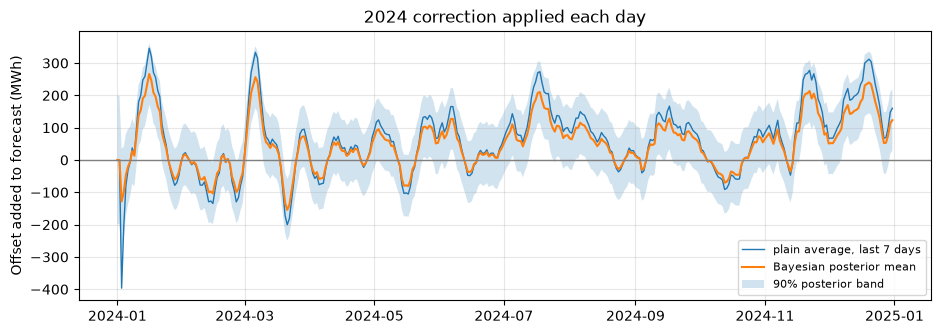

shrinkage with 7 days: posterior mean = 0.77 x plain average


In [9]:
#posterior mean vs plain average for the same window
n_show = 7 #number of days

pmean, psd = bayes_offsets(daily_va, n_show, prior_sd, day_sd) #get mean and sd

plain = window_offsets(daily_va, n_show) #offset window

fig, ax = plt.subplots(figsize=(11, 3.5))
d = pd.to_datetime(daily_va.index)

ax.plot(d, plain.values, linewidth=1, label=f"plain average, last {n_show} days")
ax.plot(d, pmean.values, linewidth=1.5, label="Bayesian posterior mean")

ax.fill_between(d, (pmean - 1.645 * psd).values, (pmean + 1.645 * psd).values, alpha=0.2, label="90% posterior band")

ax.axhline(0, color="gray", linewidth=1)
ax.set_ylabel("Offset added to forecast (MWh)")
ax.set_title("2024 correction applied each day")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.show()

print(f"shrinkage with {n_show} days: posterior mean = {(n_show / day_sd**2) / (1 / prior_sd**2 + n_show / day_sd**2):.2f} x plain average")

- `prior_sd` = 121 MWh, the size of month-to-month surprises from notebook 05.
- `day_sd` = 175 MWh, the scatter of daily errors on the training years.

With 7 days of data:
- the posterior mean is 0.77 x the plain average 
- The prior pulls it about a quarter back toward zero would expect that with 28 days it would trust the data more

This updated is the most accurate so far:
- MAPE 2.63–2.66% for every window vs 2.68% for the best plain average. 
- Shrinkage helps most for short windows: 3 days goes from 2.77% (plain) to 2.63% (Bayesian) likely because it stops being influenced as much to a few unusual days
- The intervals widen by the offset uncertainty: 808–840 MWh vs 800, and coverage goes up to 92–94%. That's over 90%, so the offset uncertainty is a bit generous
- Cost of shrinkage is we still have bias: −10 to −28 MWh vs about 0 for the plain average. Pulling toward zero means not fully believing the offset.

We will use 14 days for the better coverage -> MAPE 2.64%, coverage 93%. (note that 3-days has coverage of 94% so we exclude it even though it has the lowest MAPE)
    - We had a tie for MAPE that still had good coverage. I did not have something stated to choose here so went to natural extensions to say take the better coverage

In [10]:
#Now do what was chosen
# def pick(table, prefix):
#     ok = table[table["model"].str.startswith(prefix) & table["coverage_pct"].between(88, 94)]
#     return ok.loc[ok["mape_pct"].idxmin()] #okay did this and it chose 7, so without round 7 days was probably better or it was simply 7 came before 14

def pick(table, prefix):
    ok = table[table["model"].str.startswith(prefix) & table["coverage_pct"].between(88, 94)].copy()
    ok['coverage_gap'] = (ok["coverage_pct"] - 90).abs()
    ok['abs_bias'] = ok['bias_mwh'].abs()
    return ok.sort_values(["mape_pct", "coverage_gap", "abs_bias", "width_mwh"]).iloc[0]

best_w = pick(window_table, "+ average") #use function
best_b = pick(bayes_table, "+ Bayesian")

BEST_WINDOW = int(best_w["model"].split()[-2]) #"... last 14 days" -> 14
BEST_BAYES = int(best_b["model"].split()[-2])

print(f"simple correction: last {BEST_WINDOW} days  (MAPE {best_w['mape_pct']}%, coverage {best_w['coverage_pct']}%)")
print(f"Bayesian update: last {BEST_BAYES} days  (MAPE {best_b['mape_pct']}%, coverage {best_b['coverage_pct']}%)")

simple correction: last 14 days  (MAPE 2.68%, coverage 91.45%)
Bayesian update: last 14 days  (MAPE 2.64%, coverage 92.61%)


got the 14 days for both, bayesian does a little better

## Step 4 -> Test 

Have everything chosen now so we now test with:
- the base forecast is `m4` refit on 2021–2024 (`idata_m4_final`, from notebook 05's test section) 
- the corrections use the test period demand as it arrives following the D-2 rule.
- Note no correction at first since we need a couple of days to pass for the correction to have data

Compared on the same hours with EIA and notebook 04's GBM (from `predictions_test`).

In [11]:
y_te = predictive_draws(idata_m4_final, build_X(test), slot_index(test), seed=SEED) #get values

a_te = test["demand_mwh"].values #actual values
daily_te, dates_te = daily_errors(y_te, test) #daily errors for test data

off_naive = window_offsets(daily_te, BEST_WINDOW) #window offsets
y_te_naive = apply_offsets(y_te, dates_te, off_naive)

pmean_te, psd_te = bayes_offsets(daily_te, BEST_BAYES, prior_sd, day_sd) #offset values
y_te_bayes = apply_offsets(y_te, dates_te, pmean_te, psd_te)

#predictions from table
preds = con.sql("SELECT * FROM predictions_test ORDER BY period_utc").df()
print("same hours:", (preds["period_utc"].values == test["period_utc"].values).all())  #expect True

#values that have data
has_eia = preds["eia_forecast_mwh"].notna().values

#function to get scores
def point_scores(pred, name):
    p, a = pred[has_eia], a_te[has_eia]
    return pd.DataFrame({"model": [name], "mae_mwh": [mean_absolute_error(a, p)],
                         "mape_pct": [100 * mean_absolute_percentage_error(a, p)],
                         "rmse_mwh": [root_mean_squared_error(a, p)], "bias_mwh": [np.mean(p - a)],
                         "coverage_pct": [np.nan], "width_mwh": [np.nan]}).round(2)

same hours: True


In [12]:
test_table = pd.concat([
    point_scores(preds["eia_forecast_mwh"].values, "EIA day-ahead (benchmark)"),
    point_scores(preds["pred_gbm"].values, "GBM + trend (notebook 04)"),
    scores(y_te, a_te, "Bayesian m4, no correction", has_eia),
    scores(y_te_naive, a_te, f"m4 + average error, last {BEST_WINDOW} days", has_eia),
    scores(y_te_bayes, a_te, f"m4 + Bayesian update, last {BEST_BAYES} days", has_eia),
], ignore_index=True)
test_table

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh,coverage_pct,width_mwh
0,EIA day-ahead (benchmark),138.37,1.94,181.58,6.97,NaN,NaN
1,GBM + trend (notebook 04),349.40,4.86,414.12,-337.86,NaN,NaN
2,"Bayesian m4, no correction",354.26,4.93,432.47,-321.62,59.64,781.28
3,"m4 + average error, last 14 days",189.87,2.68,244.13,-7.57,89.62,781.28
4,"m4 + Bayesian update, last 14 days",192.52,2.71,247.61,-48.79,89.77,795.00


Okay, EIA is still the best BUT we have made a huge improvement with the recent demand jumping from ~5 to ~3 in MAPE and reduced bias. For the demand the average error does better than the bayesian update. 

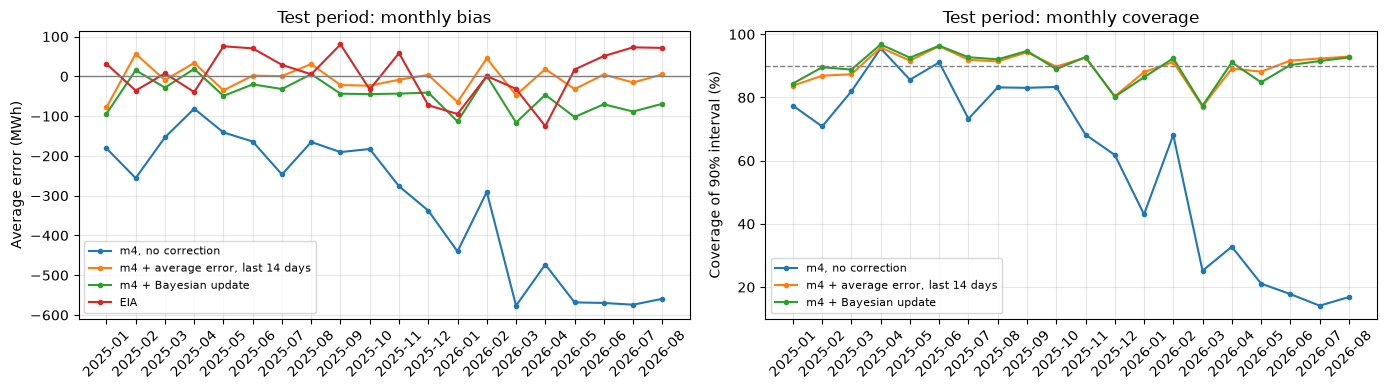

,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
bias m4,-181.0,-256.0,-153.0,-81.0,-141.0,-164.0,-247.0,-165.0,-190.0,-183.0,-276.0,-337.0,-440.0,-290.0,-577.0,-473.0,-568.0,-570.0,-574.0,-559.0
bias m4 + average,-78.0,57.0,-9.0,34.0,-35.0,2.0,1.0,31.0,-22.0,-23.0,-8.0,4.0,-65.0,45.0,-47.0,18.0,-32.0,5.0,-15.0,5.0
bias m4 + update,-94.0,15.0,-28.0,19.0,-49.0,-20.0,-32.0,6.0,-44.0,-45.0,-43.0,-41.0,-113.0,1.0,-116.0,-46.0,-102.0,-70.0,-88.0,-69.0
bias EIA,32.0,-36.0,7.0,-39.0,76.0,70.0,29.0,5.0,80.0,-33.0,59.0,-73.0,-95.0,1.0,-32.0,-125.0,17.0,51.0,73.0,72.0
coverage m4,77.0,71.0,82.0,96.0,86.0,91.0,73.0,83.0,83.0,83.0,68.0,62.0,43.0,68.0,25.0,33.0,21.0,18.0,14.0,17.0
coverage m4 + average,84.0,87.0,87.0,96.0,92.0,96.0,92.0,91.0,94.0,90.0,93.0,80.0,88.0,91.0,77.0,89.0,88.0,92.0,92.0,93.0
coverage m4 + update,84.0,90.0,89.0,97.0,93.0,96.0,93.0,92.0,95.0,89.0,93.0,80.0,86.0,92.0,77.0,91.0,85.0,90.0,92.0,93.0


In [13]:
#monthly bias and coverage through the test period
months_te = test["period_utc"].dt.tz_convert("America/Los_Angeles").dt.strftime("%Y-%m").values

def by_month(y_draws):
    lo, hi = np.percentile(y_draws, 5, axis=0), np.percentile(y_draws, 95, axis=0)
    med = np.median(y_draws, axis=0)
    return (pd.Series(med - a_te).groupby(months_te).mean(),
            pd.Series((a_te >= lo) & (a_te <= hi)).groupby(months_te).mean() * 100)

bias_base, cov_base = by_month(y_te)
bias_naive, cov_naive = by_month(y_te_naive)
bias_bayes, cov_bayes = by_month(y_te_bayes)
bias_eia = pd.Series(preds["eia_forecast_mwh"].values - a_te)[has_eia].groupby(months_te[has_eia]).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

#figure 1 is by monthly bias
axes[0].plot(bias_base.index, bias_base, marker="o", markersize=3, label="m4, no correction")
axes[0].plot(bias_naive.index, bias_naive, marker="o", markersize=3, label=f"m4 + average error, last {BEST_WINDOW} days")
axes[0].plot(bias_bayes.index, bias_bayes, marker="o", markersize=3, label="m4 + Bayesian update")
axes[0].plot(bias_eia.index, bias_eia, marker="o", markersize=3, label="EIA")

axes[0].axhline(0, color="gray", linewidth=1)

axes[0].set_ylabel("Average error (MWh)")
axes[0].set_title("Test period: monthly bias")

#figure two is monthly coverage
axes[1].plot(cov_base.index, cov_base, marker="o", markersize=3, label="m4, no correction")
axes[1].plot(cov_naive.index, cov_naive, marker="o", markersize=3, label=f"m4 + average error, last {BEST_WINDOW} days")
axes[1].plot(cov_bayes.index, cov_bayes, marker="o", markersize=3, label="m4 + Bayesian update")

axes[1].axhline(90, color="gray", linestyle="--", linewidth=1)
axes[1].set_ylabel("Coverage of 90% interval (%)")
axes[1].set_title("Test period: monthly coverage")

for ax in axes:
    ax.tick_params(axis="x", labelrotation=45)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame({"bias m4": bias_base, "bias m4 + average": bias_naive, "bias m4 + update": bias_bayes, "bias EIA": bias_eia,
              "coverage m4": cov_base, "coverage m4 + average": cov_naive, "coverage m4 + update": cov_bayes}).round(0).T

Recent demand helps and closes the gap to EIA
outline of results:

| on the same 14,560 test hours | MAPE | bias (MWh) | 90% coverage |
|---|---|---|---|
| EIA day-ahead | **1.94%** | +7 | (none) |
| GBM + trend (04) | 4.86% | −338 | (none) |
| Bayesian m4, no correction | 4.93% | −322 | 59.6% |
| **m4 + average error, last 14 days** | **2.68%** | **−8** | **89.6%** |
| m4 + Bayesian update, last 14 days | 2.71% | −49 | 89.8% |

- MAPE nearly halves (4.93% → 2.68%), and coverage comes back to ~90%, from 59.6%. 
- With the Bayesian update the monthly coverage stays within 77–97% (lowest in Dec 2025 and Mar 2026) instead of collapsing to 14–25% in 2026.
- EIA is still better: It sees recent demand too, with forecast models built for this, and may use more recent data than the conservative D−2 rule used here.

Surprisingly the simple average beats the Bayesian update model which is opposite of the valid 2024 data (2.68% vs 2.71%). 
This is likely due to the bias which is much larger for the Bayesian update, and the monthly table shows the Bayesian version staying about −45 to −115 MWh low through 2026

The prior says offsets are usually about 120 MWh which is from 2021–2023. 
In 2026 the real offset is about −570 MWh, nearly 5x the prior's typical size. So Each day the update sees a large error and the prior pulls a fixed fraction of it back toward zero for some permanent under-correction.

This is a prior–data conflict: Where the prior was reasonable for where it came from, but the data/real time moved outside it. 
On 2024, where offsets were small, the shrinkage helped. On 2026, where they're large, it hurt. Choosing on 2024 picked the method that suits small offsets.

## Summary
**Recent demand works:** correcting the forecast each day by the recent average error takes the test period from 4.93% to 2.68% MAPE 
    - it removes/reduces the bias and restores ~90% interval coverage which we couldn't close in the previous notebook

**We learned from the Bayesian version:** the shrinking toward the prior helped on 2024 (small offsets) and hurt on 2025–26 (offsets 5x larger than the prior expected). So we shouldn't just drop the prior but adjust it to grow with us as well, maybe:
- a wider or heavier-tailed prior (e.g. Student-t) that stops shrinking once errors are clearly large
- learning `prior_sd` from a rolling window
- a model where the offset can evolve

**Still best-case vs EIA:** actual weather, not forecast weather. That's the next fair-comparison step (notebook 04's "round 2"), and it would make every model here worse.

**Other limitations:**
- the D−2 rule is conservative (EIA has more recent data than that);
- the offset is the same for every hour of a day since we averaged.  Although the 2025–26 shifts did look like constant all-day load so that suits this
- the 88–94% coverage window in the rule was a judgment call

In [14]:
con.close()